In [2]:
#gears can only train on one cell type, so we subset that cell type in the beginning
import scanpy as sc

canonical = sc.read_h5ad(
    "/mnt/scratche/slow/halab/Hana/Data/Pert/STATE/Replogle_Nadig/processed_data/replogle_full_trained.h5ad",
    backed="r"
)
target_genes = set(canonical.var_names)
print(len(target_genes)) 

6642


In [3]:
import json

val_genes = set(json.load(open("canonical_val_genes.json")))
test_genes = set(json.load(open("canonical_test_genes.json")))
print(f"Val: {len(val_genes)}, Test: {len(test_genes)}")

Val: 115, Test: 384


In [4]:
raw_adata = sc.read_h5ad("/mnt/scratche/slow/halab/Hana/Data/Pert/STATE/Replogle_Nadig/replogle.h5ad")

raw_rpe1 = raw_adata[raw_adata.obs["cell_line"] == "rpe1"].copy()
gene_mask = raw_rpe1.var_names.isin(target_genes)
raw_rpe1_6642 = raw_rpe1[:, gene_mask].copy()
print(raw_rpe1_6642.shape)

(173737, 6642)


In [120]:
raw_adata

AnnData object with n_obs × n_vars = 643413 × 6642
    obs: 'gem_group', 'gene', 'gene_id', 'transcript', 'gene_transcript', 'sgID_AB', 'mitopercent', 'UMI_count', 'z_gemgroup_UMI', 'cell_line'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg'
    obsm: 'X_hvg'

In [5]:
import scipy.sparse as sp

def build_condition(gene_val):
    if gene_val in ["non-targeting", "ctrl"]:
        return "ctrl"
    return f"{gene_val}+ctrl"

raw_rpe1_6642.obs["condition"] = raw_rpe1_6642.obs["gene"].apply(build_condition)
raw_rpe1_6642.obs["cell_type"] = "rpe1"
if "gene_name" not in raw_rpe1_6642.var.columns:
    raw_rpe1_6642.var["gene_name"] = raw_rpe1_6642.var_names
if not sp.issparse(raw_rpe1_6642.X):
    raw_rpe1_6642.X = sp.csr_matrix(raw_rpe1_6642.X)

In [6]:
raw_rpe1_6642

AnnData object with n_obs × n_vars = 173737 × 6642
    obs: 'gem_group', 'gene', 'gene_id', 'transcript', 'gene_transcript', 'sgID_AB', 'mitopercent', 'UMI_count', 'z_gemgroup_UMI', 'cell_line', 'condition', 'cell_type'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'gene_name'
    uns: 'hvg'
    obsm: 'X_hvg'

In [7]:
from gears import PertData

pert_data = PertData("./data_gears_matched_6642")
pert_data.new_data_process(dataset_name="rpe1_6642_matched", adata=raw_rpe1_6642)
pert_data.prepare_split(split="simulation", seed=1)
print(pert_data.adata.shape) 

/Users/aliee01/Enter/envs/sc-env/lib/python3.11/site-packages/torch_geometric/__init__.py:4: UserWarning: An issue occurred while importing 'pyg-lib'. Disabling its usage. Stacktrace: Could not load this library: /home/aliee01/Enter/envs/sc-env/lib/python3.11/site-packages/libpyg.so
  import torch_geometric.typing
/Users/aliee01/Enter/envs/sc-env/lib/python3.11/site-packages/torch_geometric/__init__.py:4: UserWarning: An issue occurred while importing 'torch-scatter'. Disabling its usage. Stacktrace: Could not load this library: /home/aliee01/Enter/envs/sc-env/lib/python3.11/site-packages/torch_scatter/_version_cuda.so
  import torch_geometric.typing
/Users/aliee01/Enter/envs/sc-env/lib/python3.11/site-packages/torch_geometric/__init__.py:4: UserWarning: An issue occurred while importing 'torch-sparse'. Disabling its usage. Stacktrace: Could not load this library: /home/aliee01/Enter/envs/sc-env/lib/python3.11/site-packages/torch_sparse/_version_cuda.so
  import torch_geometric.typing


C7orf26+ctrl


 30%|██▉       | 447/1500 [05:21<10:39,  1.65it/s]

FAU+ctrl


 70%|██████▉   | 1048/1500 [09:49<02:52,  2.62it/s]

SEM1+ctrl


 79%|███████▉  | 1185/1500 [10:38<01:42,  3.07it/s]

AC118549.1+ctrl


100%|██████████| 1500/1500 [11:59<00:00,  2.09it/s]
Done!
Saving new dataset pyg object at ./data_gears_matched_6642/rpe1_6642_matched/data_pyg/cell_graphs.pkl
Done!
Creating new splits....
Saving new splits at ./data_gears_matched_6642/rpe1_6642_matched/splits/rpe1_6642_matched_simulation_1_0.75.pkl
Simulation split test composition:
combo_seen0:0
combo_seen1:0
combo_seen2:0
unseen_single:375
Done!


(173737, 6642)


In [8]:
def condition_to_geneset(cond):
    return set(g for g in cond.split("+") if g != "ctrl")

all_conditions = pert_data.adata.obs["condition"].unique().tolist()
new_val_conds, new_test_conds, new_train_conds = [], [], []

for cond in all_conditions:
    if cond == "ctrl":
        new_train_conds.append(cond)
        continue
    genes_in_cond = condition_to_geneset(cond)
    if genes_in_cond & test_genes:
        new_test_conds.append(cond)
    elif genes_in_cond & val_genes:
        new_val_conds.append(cond)
    else:
        new_train_conds.append(cond)

pert_data.set2conditions = {"train": new_train_conds, "val": new_val_conds, "test": new_test_conds}
cond_to_split = {c: "train" for c in new_train_conds}
cond_to_split.update({c: "val" for c in new_val_conds})
cond_to_split.update({c: "test" for c in new_test_conds})
pert_data.adata.obs["split"] = pert_data.adata.obs["condition"].map(cond_to_split)

print("Unassigned:", pert_data.adata.obs["split"].isna().sum())
print(f"train={len(new_train_conds)}, val={len(new_val_conds)}, test={len(new_test_conds)}")

# Verify exact match
actual_test_genes = set()
for c in new_test_conds:
    actual_test_genes.update(condition_to_geneset(c))
print("Test genes match exactly:", actual_test_genes == test_genes)

pert_data.get_dataloader(batch_size=64, test_batch_size=64)

Creating dataloaders....
Done!


Unassigned: 0
train=1098, val=90, test=312
Test genes match exactly: False


In [9]:
from gears import GEARS
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
gears_model = GEARS(pert_data, device=device)
gears_model.model_initialize(hidden_size=64)
gears_model.train(epochs=20)

Downloading...
100%|██████████| 60.7M/60.7M [00:02<00:00, 27.5MiB/s]
Extracting tar file...
Done!
Start Training...
Epoch 1 Step 1 Train Loss: 0.5015
Epoch 1 Step 51 Train Loss: 0.5073
Epoch 1 Step 101 Train Loss: 0.5318
Epoch 1 Step 151 Train Loss: 0.5189
Epoch 1 Step 201 Train Loss: 0.4716
Epoch 1 Step 251 Train Loss: 0.4834
Epoch 1 Step 301 Train Loss: 0.4900
Epoch 1 Step 351 Train Loss: 0.5081
Epoch 1 Step 401 Train Loss: 0.4858
Epoch 1 Step 451 Train Loss: 0.4768
Epoch 1 Step 501 Train Loss: 0.4871
Epoch 1 Step 551 Train Loss: 0.4823
Epoch 1 Step 601 Train Loss: 0.4902
Epoch 1 Step 651 Train Loss: 0.4733
Epoch 1 Step 701 Train Loss: 0.4923
Epoch 1 Step 751 Train Loss: 0.4730
Epoch 1 Step 801 Train Loss: 0.5020
Epoch 1 Step 851 Train Loss: 0.5115
Epoch 1 Step 901 Train Loss: 0.4815
Epoch 1 Step 951 Train Loss: 0.4948
Epoch 1 Step 1001 Train Loss: 0.4841
Epoch 1 Step 1051 Train Loss: 0.4515
Epoch 1 Step 1101 Train Loss: 0.4876
Epoch 1 Step 1151 Train Loss: 0.4966
Epoch 1 Step 1201 T

KeyError: 'VPS35+ctrl'

In [10]:
gears_model.save_model("./gears_model_RPE1_6642")

In [34]:
from gears.utils import create_cell_graph_for_prediction

# def normalize_log(X, target_sum=1e4):
#     X = np.asarray(X, dtype=float)
#     X = np.clip(X, 0, None)  # clip negative predictions -- fixes the NaN bug
#     totals = X.sum(axis=1, keepdims=True)
#     totals[totals == 0] = 1
#     return np.log1p(X / totals * target_sum)

def get_predictions_for_indices(gears_model, genes, ctrl_adata, gene_list, device, indices):
    gene_arr = np.array(gene_list)
    pert_idx = [np.where(g == gene_arr)[0][0] for g in genes]
    Xs = ctrl_adata[indices, :].X.toarray()
    cell_graphs = [create_cell_graph_for_prediction(X, pert_idx, genes).to(device) for X in Xs]
    loader = PyGDataLoader(cell_graphs, batch_size=64, shuffle=False)
    preds = []
    with torch.no_grad():
        for batch_data in loader:
            batch_data = batch_data.to(device)
            preds.append(gears_model.model(batch_data).cpu().numpy())
    return np.concatenate(preds, axis=0)

gene_list = gears_model.gene_list
ctrl_adata = pert_data.adata[pert_data.adata.obs["condition"] == "ctrl"].copy()
rng = np.random.default_rng(0)
fixed_indices = rng.choice(ctrl_adata.n_obs, size=min(300, ctrl_adata.n_obs), replace=False)
print(f"Fixed control pool: {len(fixed_indices)} cells")

Fixed control pool: 300 cells


In [46]:
results_all = []
still_failing = []

for cond in pert_data.set2conditions["test"]:
    genes = [g for g in cond.split("+") if g != "ctrl"]
    if any(g not in gene_list for g in genes):
        continue
    try:
        pred_matrix = get_predictions_for_indices(gears_model, genes, ctrl_adata, gene_list, device, fixed_indices)
        real_cells = pert_data.adata[pert_data.adata.obs["condition"] == cond]
        if real_cells.n_obs < 10:
            continue
        real_X = real_cells.X.toarray() if hasattr(real_cells.X, "toarray") else real_cells.X

        results_all.append({
            "condition": cond,
            "total_var_pred": np.var((pred_matrix), axis=0).sum(), #normalize_log
            "total_var_real": np.var((real_X), axis=0).sum(), #normalize_log
            "n_cells": real_cells.n_obs,
        })
    except Exception as e:
        still_failing.append((cond, str(e)))
    torch.cuda.empty_cache()

print(f"{len(results_all)} succeeded, {len(still_failing)} failed")
if still_failing:
    print("Sample failures:", still_failing[:5])

gears_var_df = pd.DataFrame(results_all).set_index("condition")
print(f"NaN check: {gears_var_df['total_var_pred'].isna().sum()}")
gears_var_df.to_csv("gears_var_final.csv")

301 succeeded, 0 failed
NaN check: 0


In [47]:
r, p = pearsonr(gears_var_df["total_var_real"], gears_var_df["total_var_pred"])
slope, intercept = np.polyfit(gears_var_df["total_var_real"], gears_var_df["total_var_pred"], 1)
print(f"GEARS (n={len(gears_var_df)}): r={r:.3f}, p={p:.4g}, slope={slope:.3f}")

GEARS (n=301): r=0.001, p=0.9841, slope=0.000


In [113]:
len(pred.obs["condition"].unique())

301

In [114]:
import anndata as ad
import pandas as pd
import numpy as np
import torch

real_parts = []
pred_parts = []
failed = []

for test_cond in pred.obs["condition"].unique():
    genes = [g for g in test_cond.split("+") if g != "ctrl"]
    if any(g not in gene_list for g in genes):
        continue

    real_cells = pert_data.adata[pert_data.adata.obs["condition"] == test_cond].copy()
    # if real_cells.n_obs < 10:
    #     continue

    try:
        pred_X = get_predictions_for_indices(gears_model, genes, ctrl_adata, gene_list, device, fixed_indices)
    except Exception as e:
        failed.append((test_cond, str(e)))
        continue

    pred_cells = ad.AnnData(
        X=pred_X,
        var=pd.DataFrame(index=gene_list),
        obs=pd.DataFrame({"condition": [test_cond] * pred_X.shape[0]})
    )

    real_parts.append(real_cells)
    pred_parts.append(pred_cells)
    torch.cuda.empty_cache()

print(f"{len(real_parts)} conditions succeeded, {len(failed)} failed")

real = ad.concat(real_parts)
pred = ad.concat(pred_parts)

print(real)
print(pred)

301 conditions succeeded, 0 failed
AnnData object with n_obs × n_vars = 33851 × 6642
    obs: 'gem_group', 'gene', 'gene_id', 'transcript', 'gene_transcript', 'sgID_AB', 'mitopercent', 'UMI_count', 'z_gemgroup_UMI', 'cell_line', 'condition', 'cell_type', 'dose_val', 'control', 'condition_name', 'split'
    obsm: 'X_hvg'
AnnData object with n_obs × n_vars = 90300 × 6642
    obs: 'condition'


In [125]:
real.obs.gene.unique()

['GPS2', 'MEN1', 'PGAM5', 'TFAM', 'NOLC1', ..., 'SAMM50', 'CTR9', 'SLBP', 'SF3B2', 'POLE']
Length: 301
Categories (301, object): ['ACTR8', 'AGBL5', 'AHCTF1', 'ALG1', ..., 'ZNF143', 'ZNHIT3', 'ZW10', 'ZWINT']

In [123]:
cin_damage_genes = [
    "UBE2T", "PARP1", "XRCC5", "SMC4", "NCAPG", "MAD2L1", "NPM1", "RPA3",
    "MCM7", "PRKDC", "SMC2", "KIF20B", "RRM1", "FEN1", "NCAPD2", "CBX5",
    "NUSAP1", "TOP2A", "BRCA1", "BIRC5", "SMC1A",
]

genes_present_pred = [g for g in cin_damage_genes if g in pred.var_names]
genes_present_real = [g for g in cin_damage_genes if g in real.var_names]

print(f"Pred: {len(genes_present_pred)}/{len(cin_damage_genes)} found")
print(f"Real: {len(genes_present_real)}/{len(cin_damage_genes)} found")



sc.tl.score_genes(pred, gene_list=genes_present_pred, score_name="cin_damage_score")
sc.tl.score_genes(real, gene_list=genes_present_real, score_name="cin_damage_score")

Pred: 21/21 found
Real: 21/21 found


In [124]:
# --- Training-mean CIN reference (marginalization target) ---
train_genes = set()
for c in pert_data.set2conditions["train"]:
    if c != "ctrl":
        train_genes.update(g for g in c.split("+") if g != "ctrl")

train_cells = pert_data.adata[
    pert_data.adata.obs["condition"].isin(pert_data.set2conditions["train"])
].copy()

if "cin_damage_score" not in train_cells.obs.columns:
    sc.tl.score_genes(train_cells, gene_list=genes_present_real, score_name="cin_damage_score")

train_mean_cin = train_cells.obs["cin_damage_score"].mean()
print(f"Training mean CIN: {train_mean_cin:.4f}")

# --- GEARS's official .predict() mean estimate, scored the same way ---
official_pred_scores = []
for cond in pred.obs["condition"].unique():
    genes = [g for g in cond.split("+") if g != "ctrl"]
    try:
        pred_dict = gears_model.predict([genes])
    except Exception:
        continue
    pred_key = "_".join(genes)
    if pred_key not in pred_dict:
        pred_key = list(pred_dict.keys())[0]
    mean_vector = np.asarray(pred_dict[pred_key]).reshape(1, -1)

    tmp = ad.AnnData(X=mean_vector, var=pd.DataFrame(index=gene_list))
    sc.tl.score_genes(tmp, gene_list=genes_present_real, score_name="cin_damage_score")
    official_pred_scores.append(tmp.obs["cin_damage_score"].values[0])

official_pred_scores = np.array(official_pred_scores)
official_mean = official_pred_scores.mean()
print(f"GEARS .predict() mean CIN (across {len(official_pred_scores)} conditions): {official_mean:.4f}")

Training mean CIN: -0.0344
GEARS .predict() mean CIN (across 301 conditions): -0.0436


GEARS: r=0.001, p=0.9841, slope=0.000, n=301
Training mean CIN: -0.0344
GEARS .predict() mean CIN: -0.0436
Saved.


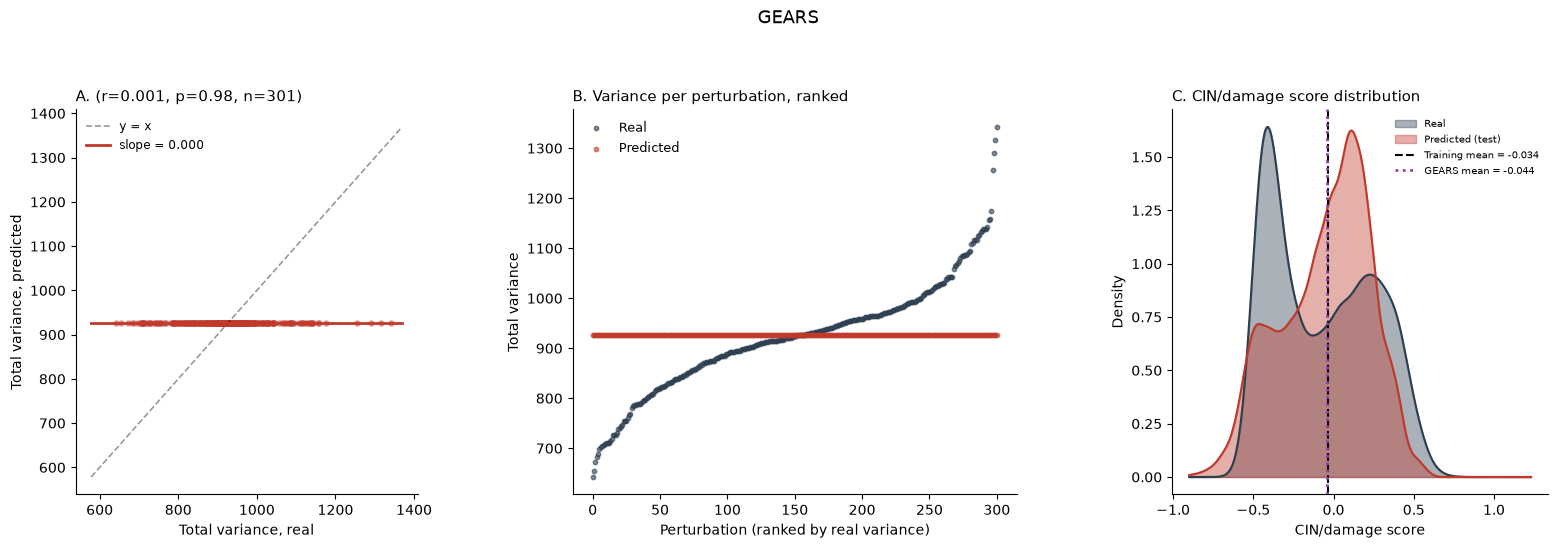

In [119]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import anndata as ad
import scanpy as sc
from scipy.stats import pearsonr, gaussian_kde

REAL_COLOR = "#2c3e50"
PRED_COLOR = "#c0392b"
MODEL_NAME = "GEARS"

# ----------------------------------------------------------------------
# Compute total variance per condition (Panels A and B)
# ----------------------------------------------------------------------
results = []
for cond in pred.obs["condition"].unique():
    real_sub = real[real.obs["condition"] == cond].X
    pred_sub = pred[pred.obs["condition"] == cond].X
    real_sub = real_sub.toarray() if hasattr(real_sub, "toarray") else real_sub
    pred_sub = pred_sub.toarray() if hasattr(pred_sub, "toarray") else pred_sub

    results.append({
        "condition": cond,
        "total_var_real": np.var(real_sub, axis=0).sum(),
        "total_var_pred": np.var(pred_sub, axis=0).sum(),
    })

df = pd.DataFrame(results).set_index("condition")
r, p = pearsonr(df["total_var_real"], df["total_var_pred"])
slope, intercept = np.polyfit(df["total_var_real"], df["total_var_pred"], 1)
print(f"{MODEL_NAME}: r={r:.3f}, p={p:.4g}, slope={slope:.3f}, n={len(df)}")

# ----------------------------------------------------------------------
# Training-mean CIN reference (marginalization target)
# ----------------------------------------------------------------------
train_cells = pert_data.adata[
    pert_data.adata.obs["condition"].isin(pert_data.set2conditions["train"])
].copy()
if "cin_damage_score" not in train_cells.obs.columns:
    sc.tl.score_genes(train_cells, gene_list=genes_present_real, score_name="cin_damage_score")
train_mean_cin = train_cells.obs["cin_damage_score"].mean()
print(f"Training mean CIN: {train_mean_cin:.4f}")

# ----------------------------------------------------------------------
# GEARS's official .predict() mean estimate, scored the same way
# ----------------------------------------------------------------------
official_pred_scores = []
for cond in pred.obs["condition"].unique():
    genes = [g for g in cond.split("+") if g != "ctrl"]
    try:
        pred_dict = gears_model.predict([genes])
    except Exception:
        continue
    pred_key = "_".join(genes)
    if pred_key not in pred_dict:
        pred_key = list(pred_dict.keys())[0]
    mean_vector = np.asarray(pred_dict[pred_key]).reshape(1, -1)

    tmp = ad.AnnData(X=mean_vector, var=pd.DataFrame(index=gene_list))
    sc.tl.score_genes(tmp, gene_list=genes_present_real, score_name="cin_damage_score")
    official_pred_scores.append(tmp.obs["cin_damage_score"].values[0])

official_pred_scores = np.array(official_pred_scores)
official_mean = official_pred_scores.mean()
print(f"GEARS .predict() mean CIN: {official_mean:.4f}")

# ----------------------------------------------------------------------
# Figure
# ----------------------------------------------------------------------
fig = plt.figure(figsize=(19, 5))
gs = gridspec.GridSpec(1, 3, width_ratios=[1, 1.3, 1.1], wspace=0.4)

# Panel A: slope plot
axA = fig.add_subplot(gs[0])
axA.scatter(df["total_var_real"], df["total_var_pred"], s=14, alpha=0.4, color=PRED_COLOR)
lims = [df["total_var_real"].min()*0.9, df["total_var_real"].max()*1.02]
axA.plot(lims, lims, 'k--', alpha=0.4, lw=1.2, label="y = x")
fit_x = np.array(lims)
axA.plot(fit_x, intercept + slope*fit_x, color=PRED_COLOR, lw=2, label=f"slope = {slope:.3f}")
axA.set_xlabel("Total variance, real"); axA.set_ylabel("Total variance, predicted")
axA.set_title(f"A. (r={r:.3f}, p={p:.2g}, n={len(df)})", fontsize=11, loc="left")
axA.legend(fontsize=8.5, frameon=False); axA.spines[['top','right']].set_visible(False)

# Panel B: sorted variance per perturbation
axB = fig.add_subplot(gs[1])
df_sorted = df.sort_values("total_var_real").reset_index(drop=True)
x = np.arange(len(df_sorted))
axB.scatter(x, df_sorted["total_var_real"], s=10, alpha=0.6, color=REAL_COLOR, label="Real")
axB.scatter(x, df_sorted["total_var_pred"], s=10, alpha=0.6, color=PRED_COLOR, label="Predicted")
axB.set_xlabel("Perturbation (ranked by real variance)"); axB.set_ylabel("Total variance")
axB.set_title("B. Variance per perturbation, ranked", fontsize=11, loc="left")
axB.legend(fontsize=9, frameon=False); axB.spines[['top','right']].set_visible(False)

# Panel C: CIN score density, with training-mean and .predict()-mean reference lines
axC = fig.add_subplot(gs[2])
real_scores = real.obs["cin_damage_score"].values
pred_scores = pred.obs["cin_damage_score"].values

x_range = np.linspace(
    -0.9,
    max(real_scores.max(), pred_scores.max()) + 0.2,
    300
)

kde_real = gaussian_kde(real_scores)
kde_pred = gaussian_kde(pred_scores)
axC.fill_between(x_range, kde_real(x_range), alpha=0.4, color=REAL_COLOR, label="Real")
axC.plot(x_range, kde_real(x_range), color=REAL_COLOR, lw=1.5)
axC.fill_between(x_range, kde_pred(x_range), alpha=0.4, color=PRED_COLOR, label="Predicted (test)")
axC.plot(x_range, kde_pred(x_range), color=PRED_COLOR, lw=1.5)

axC.axvline(train_mean_cin, color="black", linestyle="--", linewidth=1.5,
            label=f"Training mean = {train_mean_cin:.3f}")
axC.axvline(official_mean, color="#8e44ad", linestyle=":", linewidth=2,
            label=f"GEARS mean = {official_mean:.3f}")

axC.set_xlabel("CIN/damage score"); axC.set_ylabel("Density")
axC.set_title("C. CIN/damage score distribution", fontsize=11, loc="left")
axC.legend(frameon=False, fontsize=7.5); axC.spines[['top','right']].set_visible(False)

fig.suptitle(f"{MODEL_NAME}", fontsize=13, y=1.08)
plt.tight_layout()
plt.savefig("gears_3panel_final.pdf", dpi=220, bbox_inches="tight", transparent=True)
print("Saved.")

In [73]:
# real.write('./Data/real_gears.h5ad')
# pred.write('./Data/pred_gears.h5ad')